# An introduction to the DC-emulator

This notebook serves as a quick tutorial for how to use the DCGAN model to generate super-resolved simulations. 


In [5]:
import matplotlib.pyplot as plt
import numpy as np
import torch


from src.DCGAN import DCGAN
from src.utils import dis2pos


### Setting up the model

When constructing the model instance, you have the option of setting the device to gpu if you have one available. This will push the upscaling done by the model to the GPU. 



In [11]:
model = DCGAN(
    state_path="src/state.pt",
    device="cpu")

dz = 1e-5

sigma8 = 0.778
BoxSize = 1000.
Ngrid_LR = 256
Ngrid_SR = 2 * Ngrid_LR

### Generating fields 

You can use the model to generate the displacement field and its corresponding velocity field of snapshots. To do this, you must supply the model with a simulation snapshot and the value of $\sigma_8$. You also need to supply the model with an unperturbed initial condition file, which serves as $\bf{q}$ in 

$$
\bf{x} = \psi + \bf{q}
$$

For the velocity, you must also supply a time interval $dz$, which is used in the calculation of the velocity:
$$
\bf{v} = a \frac{d\bf{x}}{dt}
$$



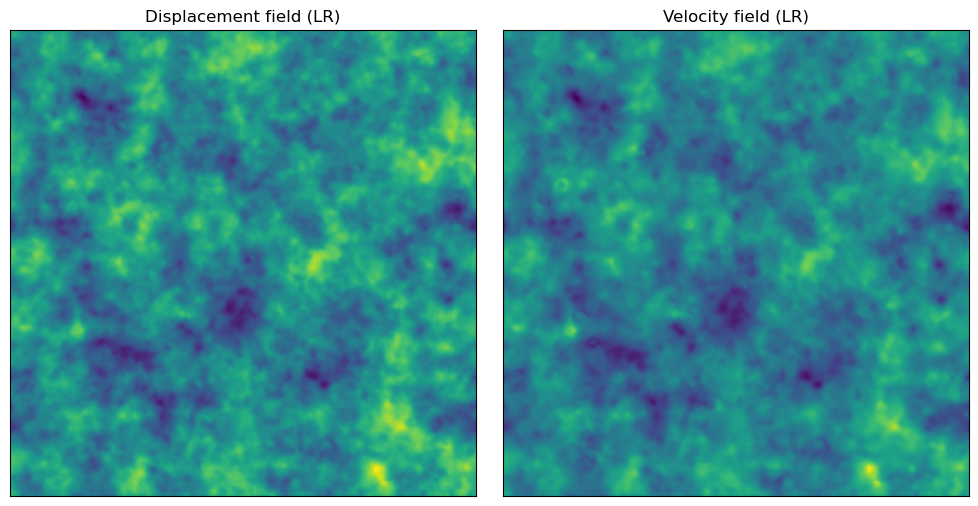

In [ ]:
# Define simulation snapshot to upscale, along with unperturbed initial conditions
file = "/mn/stornext/d8/data/dennisfr/DCGAN/data/node8/su_snap009_cdm"
file_q = "/mn/stornext/d8/data/dennisfr/DCDATA/node0/gevolution/ics.0"

# Compute the velocity field
vel_LR = model.velocity(file, file_q, sigma8=0.778, dz=dz, upscale=False)

# Compute displacement field and convert to particle positions
dis_LR = model.position(file, file_q, sigma8=0.778, upscale=False)
pos_LR = dis2pos(dis_LR, BoxSize, Ngrid_LR).reshape((3, Ngrid_LR**3))
pos_LR = np.moveaxis(pos_LR, -1, 0)



fig, ax = plt.subplots(ncols=2, figsize=(10, 5))

ax[0].imshow(dis_LR[0,0])
ax[0].set_title("Displacement field (LR)")

ax[1].imshow(vel_LR[0,0])
ax[1].set_title("Velocity field (LR)")

[[axi.set_xticks([]), axi.set_yticks([])] for axi in ax]

plt.tight_layout()


### Upscaling a snapshot

To upscale a snapshot, simply call the `position` method of the model with `upscale=True`. This will return the displacement field at high resolution, which can then be converted to particle positions.

4/64 done
8/64 done
12/64 done
16/64 done
20/64 done
24/64 done
28/64 done
32/64 done
36/64 done
40/64 done
44/64 done
48/64 done
52/64 done
56/64 done
60/64 done
64/64 done
4/64 done
8/64 done
12/64 done
16/64 done
20/64 done
24/64 done
28/64 done
32/64 done
36/64 done
40/64 done
44/64 done
48/64 done
52/64 done
56/64 done
60/64 done
64/64 done
4/64 done
8/64 done
12/64 done
16/64 done
20/64 done
24/64 done
28/64 done
32/64 done
36/64 done
40/64 done
44/64 done
48/64 done
52/64 done
56/64 done
60/64 done
64/64 done


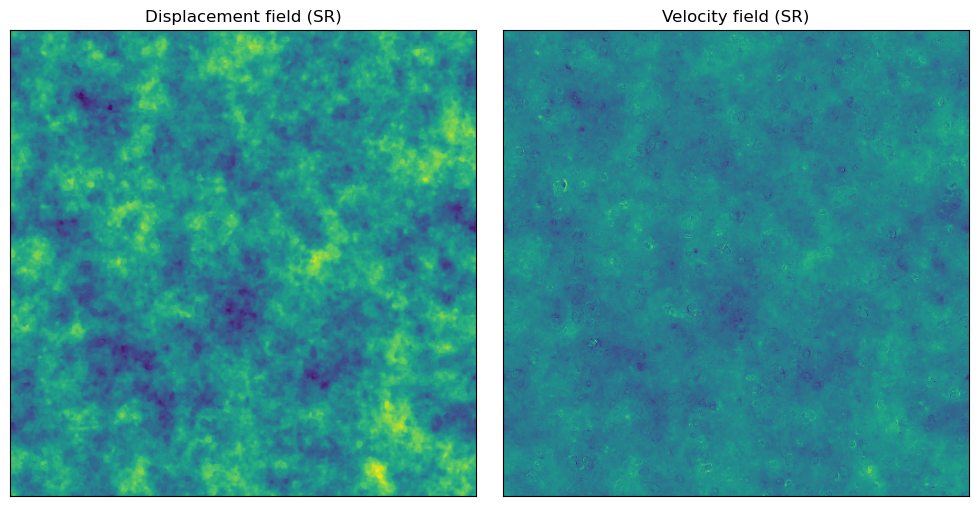

In [12]:
# Compute the velocity field
vel_SR = model.velocity(file, file_q, sigma8=0.778, dz=dz, upscale=True)

# Compute displacement field and convert to particle positions
dis_SR = model.position(file, file_q, sigma8=0.778, upscale=True)
pos_SR = dis2pos(dis_SR, BoxSize, Ngrid_SR).reshape((3, Ngrid_SR**3))
pos_SR = np.moveaxis(pos_SR, -1, 0)



fig, ax = plt.subplots(ncols=2, figsize=(10, 5))

ax[0].imshow(dis_SR[0,0])
ax[0].set_title("Displacement field (SR)")

ax[1].imshow(vel_SR[0,0])
ax[1].set_title("Velocity field (SR)")

[[axi.set_xticks([]), axi.set_yticks([])] for axi in ax]

plt.tight_layout()
